# XGBoost sobre outputs V2 de `10.try`

Este notebook entrena el mismo `XGBClassifier` que quedó fijado como referencia en `7. Arboles/i1_VS_i2_VS_i3 en arboles.ipynb`, pero usando específicamente los outputs:

- `01_preprocesamiento_v2_seguro_arboles` -> `processed/v2_tree_safe`
- `03_preprocesamiento_v2_fisica_por_jets` -> `processed/v2_physics_by_jet`

La comparación final se hace contra los resultados ya reportados en `7. Arboles/i1_VS_i2_VS_i3 en arboles.ipynb` para `i1`, `i2_arboles` e `i3_arboles`.


In [1]:
from __future__ import annotations

import json
import os
import time
from pathlib import Path

os.environ.setdefault("MPLCONFIGDIR", "/tmp/matplotlib")

import matplotlib.pyplot as plt
from IPython.display import display
import numpy as np
import pandas as pd
from sklearn.metrics import accuracy_score, f1_score, precision_score, recall_score, roc_auc_score
from xgboost import XGBClassifier

pd.set_option("display.max_columns", 120)
pd.set_option("display.width", 200)

SEED = 42
np.random.seed(SEED)

BEST_XGB_PARAMS = {
    "objective": "binary:logistic",
    "eval_metric": "logloss",
    "random_state": SEED,
    "learning_rate": 0.05,
    "n_estimators": 400,
    "max_depth": 6,
    "scale_pos_weight": 1.5346,
    "subsample": 0.9,
    "colsample_bytree": 0.9,
    "tree_method": "hist",
    "n_jobs": -1,
    "missing": np.nan,
}

NOTEBOOK_REFERENCE_RESULTS = [
    {
        "dataset": "i1",
        "result_origin": "notebook_7_arboles",
        "source": "7.Arboles/i1_VS_i2_VS_i3",
        "accuracy": 0.8311,
        "precision": 0.7347,
        "recall": 0.7937,
        "f1": 0.7631,
        "auc": 0.9057,
        "ams": 1.0394,
        "ams_threshold": 0.8772,
        "fit_seconds": 10.2505,
        "feature_count": 26,
        "train_nan_count": 0,
        "valid_nan_count": 0,
    },
    {
        "dataset": "i2_arboles",
        "result_origin": "notebook_7_arboles",
        "source": "7.Arboles/i1_VS_i2_VS_i3",
        "accuracy": 0.8356,
        "precision": 0.7420,
        "recall": 0.7975,
        "f1": 0.7688,
        "auc": 0.9090,
        "ams": 1.0868,
        "ams_threshold": 0.8739,
        "fit_seconds": 10.9121,
        "feature_count": 33,
        "train_nan_count": 1422313,
        "valid_nan_count": 157739,
    },
    {
        "dataset": "i3_arboles",
        "result_origin": "notebook_7_arboles",
        "source": "7.Arboles/i1_VS_i2_VS_i3",
        "accuracy": 0.8354,
        "precision": 0.7424,
        "recall": 0.7958,
        "f1": 0.7682,
        "auc": 0.9093,
        "ams": 1.0861,
        "ams_threshold": 0.8611,
        "fit_seconds": 14.4198,
        "feature_count": 66,
        "train_nan_count": 1615278,
        "valid_nan_count": 179029,
    },
]


In [2]:
def find_project_root(start: Path | None = None) -> Path:
    current = (start or Path.cwd()).resolve()
    for candidate in [current, *current.parents]:
        if (candidate / "roadmap.md").exists() and (candidate / "data").is_dir():
            return candidate
    raise FileNotFoundError("No se pudo localizar la raíz del proyecto.")


def load_split_processed_dataset(processed_name: str) -> dict[str, object]:
    project_root = find_project_root()
    processed_dir = project_root / "data" / "higgs-boson" / "processed" / processed_name
    if not processed_dir.exists():
        raise FileNotFoundError(f"No se encontró el directorio procesado: {processed_dir}")

    metadata_path = processed_dir / "metadata.json"
    metadata = json.loads(metadata_path.read_text()) if metadata_path.exists() else {}

    X_train = pd.read_csv(processed_dir / "X_train_processed.csv").astype(np.float32)
    X_valid = pd.read_csv(processed_dir / "X_valid_processed.csv").astype(np.float32)
    X_test = pd.read_csv(processed_dir / "X_test_processed.csv").astype(np.float32)

    label_map = {"b": 0, "s": 1}
    y_train = pd.read_csv(processed_dir / "y_train.csv")["Label"].map(label_map).astype(np.int8)
    y_valid = pd.read_csv(processed_dir / "y_valid.csv")["Label"].map(label_map).astype(np.int8)

    train_weight = pd.read_csv(processed_dir / "train_weight.csv")["Weight"].astype(np.float64)
    valid_weight = pd.read_csv(processed_dir / "valid_weight.csv")["Weight"].astype(np.float64)

    train_event_id = pd.read_csv(processed_dir / "train_event_id.csv")["EventId"].astype(np.int64)
    valid_event_id = pd.read_csv(processed_dir / "valid_event_id.csv")["EventId"].astype(np.int64)
    test_event_id = pd.read_csv(processed_dir / "test_event_id.csv")["EventId"].astype(np.int64)

    return {
        "processed_name": processed_name,
        "processed_dir": processed_dir,
        "metadata": metadata,
        "X_train": X_train,
        "X_valid": X_valid,
        "X_test": X_test,
        "y_train": y_train,
        "y_valid": y_valid,
        "train_weight": train_weight,
        "valid_weight": valid_weight,
        "train_event_id": train_event_id,
        "valid_event_id": valid_event_id,
        "test_event_id": test_event_id,
    }


def predict_scores(model: XGBClassifier, X_frame: pd.DataFrame) -> np.ndarray:
    return model.predict_proba(X_frame)[:, 1]


def ams_score(signal_weight: np.ndarray | float, background_weight: np.ndarray | float, br: float = 10.0) -> np.ndarray:
    signal_arr = np.asarray(signal_weight, dtype=np.float64)
    background_arr = np.asarray(background_weight, dtype=np.float64)
    radicand = 2.0 * ((signal_arr + background_arr + br) * np.log1p(signal_arr / (background_arr + br)) - signal_arr)
    return np.sqrt(np.clip(radicand, a_min=0.0, a_max=None))


def find_best_ams_threshold(
    y_true: pd.Series,
    y_scores: np.ndarray,
    weights: pd.Series | np.ndarray,
    br: float = 10.0,
) -> dict[str, float | int]:
    y_array = np.asarray(y_true, dtype=np.int8)
    score_array = np.asarray(y_scores, dtype=np.float64)
    weight_array = np.asarray(weights, dtype=np.float64)

    order = np.argsort(score_array)[::-1]
    y_sorted = y_array[order]
    score_sorted = score_array[order]
    weight_sorted = weight_array[order]

    signal_cumsum = np.cumsum(np.where(y_sorted == 1, weight_sorted, 0.0))
    background_cumsum = np.cumsum(np.where(y_sorted == 0, weight_sorted, 0.0))

    candidate_mask = np.r_[score_sorted[1:] != score_sorted[:-1], True]
    candidate_indices = np.flatnonzero(candidate_mask)
    ams_values = ams_score(signal_cumsum[candidate_indices], background_cumsum[candidate_indices], br=br)

    best_position = int(np.argmax(ams_values))
    best_idx = int(candidate_indices[best_position])
    best_threshold = float(score_sorted[best_idx])
    best_pred = (score_array >= best_threshold).astype(np.int8)

    return {
        "threshold": best_threshold,
        "ams": float(ams_values[best_position]),
        "signal_weight": float(signal_cumsum[best_idx]),
        "background_weight": float(background_cumsum[best_idx]),
        "predicted_signal_count": int(best_pred.sum()),
        "predicted_background_count": int(len(best_pred) - best_pred.sum()),
        "precision": float(precision_score(y_array, best_pred, zero_division=0)),
        "recall": float(recall_score(y_array, best_pred, zero_division=0)),
        "f1": float(f1_score(y_array, best_pred, zero_division=0)),
        "candidate_threshold_count": int(len(candidate_indices)),
    }


def train_and_evaluate(dataset_name: str, dataset_bundle: dict[str, object]) -> tuple[XGBClassifier, dict[str, object]]:
    model = XGBClassifier(**BEST_XGB_PARAMS)

    X_train = dataset_bundle["X_train"]
    X_valid = dataset_bundle["X_valid"]
    y_train = dataset_bundle["y_train"]
    y_valid = dataset_bundle["y_valid"]
    valid_weight = dataset_bundle["valid_weight"]

    start_time = time.perf_counter()
    model.fit(X_train, y_train)
    fit_seconds = time.perf_counter() - start_time

    valid_scores = predict_scores(model, X_valid)
    valid_pred = model.predict(X_valid)
    ams_info = find_best_ams_threshold(y_valid, valid_scores, valid_weight)

    metrics = {
        "dataset": dataset_name,
        "result_origin": "trained_in_10_try",
        "source": "same_best_xgboost_as_7_arboles",
        "accuracy": float(accuracy_score(y_valid, valid_pred)),
        "precision": float(precision_score(y_valid, valid_pred, zero_division=0)),
        "recall": float(recall_score(y_valid, valid_pred, zero_division=0)),
        "f1": float(f1_score(y_valid, valid_pred, zero_division=0)),
        "auc": float(roc_auc_score(y_valid, valid_scores)),
        "ams": float(ams_info["ams"]),
        "ams_threshold": float(ams_info["threshold"]),
        "fit_seconds": float(fit_seconds),
        "feature_count": int(X_train.shape[1]),
        "train_nan_count": int(X_train.isna().sum().sum()),
        "valid_nan_count": int(X_valid.isna().sum().sum()),
    }
    return model, metrics


def build_comparison_table(trained_rows: list[dict[str, object]]) -> pd.DataFrame:
    comparison_df = pd.DataFrame([*NOTEBOOK_REFERENCE_RESULTS, *trained_rows])

    best_notebook_auc = max(row["auc"] for row in NOTEBOOK_REFERENCE_RESULTS)
    best_notebook_ams = max(row["ams"] for row in NOTEBOOK_REFERENCE_RESULTS)
    notebook_i3_auc = next(row["auc"] for row in NOTEBOOK_REFERENCE_RESULTS if row["dataset"] == "i3_arboles")
    notebook_i2_ams = next(row["ams"] for row in NOTEBOOK_REFERENCE_RESULTS if row["dataset"] == "i2_arboles")

    comparison_df["delta_auc_vs_best_notebook"] = comparison_df["auc"] - best_notebook_auc
    comparison_df["delta_ams_vs_best_notebook"] = comparison_df["ams"] - best_notebook_ams
    comparison_df["delta_auc_vs_i3_notebook"] = comparison_df["auc"] - notebook_i3_auc
    comparison_df["delta_ams_vs_i2_notebook"] = comparison_df["ams"] - notebook_i2_ams

    return comparison_df.sort_values(["auc", "ams", "f1"], ascending=False).reset_index(drop=True)


In [3]:
project_root = find_project_root()
results_dir = project_root / "10.try" / "results"
results_dir.mkdir(parents=True, exist_ok=True)

v2_tree_safe = load_split_processed_dataset("v2_tree_safe")
v2_physics_by_jet = load_split_processed_dataset("v2_physics_by_jet")

summary_df = pd.DataFrame(
    [
        {
            "dataset": bundle["processed_name"],
            "train_rows": len(bundle["X_train"]),
            "valid_rows": len(bundle["X_valid"]),
            "test_rows": len(bundle["X_test"]),
            "feature_count": bundle["X_train"].shape[1],
            "train_nan_count": int(bundle["X_train"].isna().sum().sum()),
            "valid_nan_count": int(bundle["X_valid"].isna().sum().sum()),
            "metadata_processed_feature_count": bundle["metadata"].get("processed_feature_count"),
        }
        for bundle in [v2_tree_safe, v2_physics_by_jet]
    ]
)

print("Resumen de los datasets V2 cargados:")
display(summary_df)


Resumen de los datasets V2 cargados:


,dataset,train_rows,valid_rows,test_rows,feature_count,train_nan_count,valid_nan_count,metadata_processed_feature_count
0,v2_tree_safe,225000,25000,550000,44,1422313,157739,44
1,v2_physics_by_jet,225000,25000,550000,86,0,0,86


In [4]:
trained_models: dict[str, XGBClassifier] = {}
trained_rows: list[dict[str, object]] = []

for dataset_name, bundle in [
    ("v2_tree_safe", v2_tree_safe),
    ("v2_physics_by_jet", v2_physics_by_jet),
]:
    model, metrics = train_and_evaluate(dataset_name, bundle)
    trained_models[dataset_name] = model
    trained_rows.append(metrics)

trained_results_df = pd.DataFrame(trained_rows).sort_values(["auc", "ams"], ascending=False).reset_index(drop=True)
print("Resultados entrenados en este notebook:")
display(trained_results_df.round(4))


Resultados entrenados en este notebook:


,dataset,result_origin,source,accuracy,precision,recall,f1,auc,ams,ams_threshold,fit_seconds,feature_count,train_nan_count,valid_nan_count
0,v2_physics_by_jet,trained_in_10_try,same_best_xgboost_as_7_arboles,0.8361,0.7436,0.7963,0.7691,0.9099,1.1079,0.9049,6.4865,86,0,0
1,v2_tree_safe,trained_in_10_try,same_best_xgboost_as_7_arboles,0.8356,0.7423,0.7969,0.7686,0.9086,1.0872,0.8783,6.3409,44,1422313,157739


Comparación final contra i1/i2/i3 del notebook 7.Arboles:


,dataset,result_origin,source,feature_count,train_nan_count,valid_nan_count,accuracy,precision,recall,f1,auc,ams,ams_threshold,fit_seconds,delta_auc_vs_best_notebook,delta_ams_vs_best_notebook,delta_auc_vs_i3_notebook,delta_ams_vs_i2_notebook
0,v2_physics_by_jet,trained_in_10_try,same_best_xgboost_as_7_arboles,86,0,0,0.8361,0.7436,0.7963,0.7691,0.9099,1.1079,0.9049,6.4865,0.0006,0.0211,0.0006,0.0211
1,i3_arboles,notebook_7_arboles,7.Arboles/i1_VS_i2_VS_i3,66,1615278,179029,0.8354,0.7424,0.7958,0.7682,0.9093,1.0861,0.8611,14.4198,0.0000,-0.0007,0.0000,-0.0007
2,i2_arboles,notebook_7_arboles,7.Arboles/i1_VS_i2_VS_i3,33,1422313,157739,0.8356,0.7420,0.7975,0.7688,0.9090,1.0868,0.8739,10.9121,-0.0003,0.0000,-0.0003,0.0000
3,v2_tree_safe,trained_in_10_try,same_best_xgboost_as_7_arboles,44,1422313,157739,0.8356,0.7423,0.7969,0.7686,0.9086,1.0872,0.8783,6.3409,-0.0007,0.0004,-0.0007,0.0004
4,i1,notebook_7_arboles,7.Arboles/i1_VS_i2_VS_i3,26,0,0,0.8311,0.7347,0.7937,0.7631,0.9057,1.0394,0.8772,10.2505,-0.0036,-0.0474,-0.0036,-0.0474


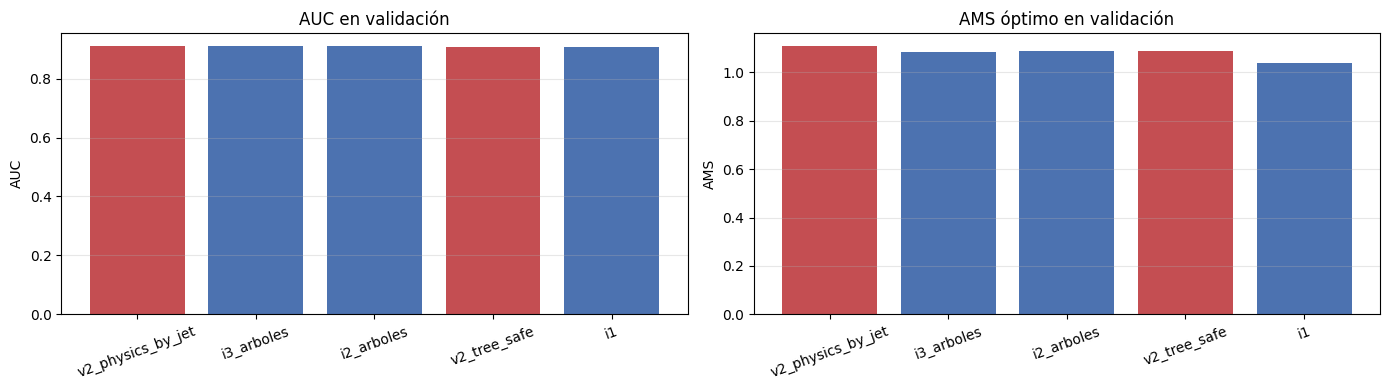

In [5]:
comparison_df = build_comparison_table(trained_rows)
comparison_columns = [
    "dataset",
    "result_origin",
    "source",
    "feature_count",
    "train_nan_count",
    "valid_nan_count",
    "accuracy",
    "precision",
    "recall",
    "f1",
    "auc",
    "ams",
    "ams_threshold",
    "fit_seconds",
    "delta_auc_vs_best_notebook",
    "delta_ams_vs_best_notebook",
    "delta_auc_vs_i3_notebook",
    "delta_ams_vs_i2_notebook",
]

print("Comparación final contra i1/i2/i3 del notebook 7.Arboles:")
display(comparison_df[comparison_columns].round(4))

fig, axes = plt.subplots(1, 2, figsize=(14, 4))
bar_colors = ["#C44E52" if origin == "trained_in_10_try" else "#4C72B0" for origin in comparison_df["result_origin"]]

axes[0].bar(comparison_df["dataset"], comparison_df["auc"], color=bar_colors)
axes[0].set_title("AUC en validación")
axes[0].set_ylabel("AUC")
axes[0].tick_params(axis="x", rotation=20)
axes[0].grid(axis="y", alpha=0.3)

axes[1].bar(comparison_df["dataset"], comparison_df["ams"], color=bar_colors)
axes[1].set_title("AMS óptimo en validación")
axes[1].set_ylabel("AMS")
axes[1].tick_params(axis="x", rotation=20)
axes[1].grid(axis="y", alpha=0.3)

plt.tight_layout()
plt.show()


In [6]:
comparison_csv_path = results_dir / "xgboost_v2_vs_i123_comparison.csv"
trained_csv_path = results_dir / "xgboost_v2_trained_only.csv"

comparison_df.to_csv(comparison_csv_path, index=False)
trained_results_df.to_csv(trained_csv_path, index=False)

summary_lines = [
    "# Resumen XGBoost V2 vs i1/i2/i3",
    "",
    "Se entrenó el mismo XGBoost de `7. Arboles/i1_VS_i2_VS_i3 en arboles.ipynb` sobre:",
    "- `v2_tree_safe`",
    "- `v2_physics_by_jet`",
    "",
    "Los resultados completos quedaron en:",
    f"- `{comparison_csv_path}`",
    f"- `{trained_csv_path}`",
    "",
    "Top por AUC:",
]

for _, row in comparison_df[["dataset", "result_origin", "auc", "ams"]].iterrows():
    summary_lines.append(
        f"- {row['dataset']} ({row['result_origin']}): AUC={row['auc']:.4f}, AMS={row['ams']:.4f}"
    )

summary_txt_path = results_dir / "xgboost_v2_vs_i123_summary.txt"
summary_txt_path.write_text("\n".join(summary_lines) + "\n")

print(f"CSV comparativo guardado en: {comparison_csv_path}")
print(f"CSV de entrenamientos V2 guardado en: {trained_csv_path}")
print(f"Resumen textual guardado en: {summary_txt_path}")


CSV comparativo guardado en: /home/santig14/fing/taa/1_TallerAA/10.try/results/xgboost_v2_vs_i123_comparison.csv
CSV de entrenamientos V2 guardado en: /home/santig14/fing/taa/1_TallerAA/10.try/results/xgboost_v2_trained_only.csv
Resumen textual guardado en: /home/santig14/fing/taa/1_TallerAA/10.try/results/xgboost_v2_vs_i123_summary.txt
